# 03. Amplitude-only sampling

**What you will achieve:** Set the spatial boundary to zero and vary the density amplitude. The final sample is normalized, so local peak-height variation need not equal the raw percentage multiplier.

**For your own data:** replace `INPUT_FILE` first; then change the brief settings cell as needed. This notebook uses `tests/fixtures/input_2.leapr` and the real TARA Core interfaces. There is no backend execution here.


## Scientific idea: changing peak amplitudes

An amplitude perturbation changes the local weight of phonon contributions in selected energy domains. In this example `max_energy_shift_mev=0`, so **spatial perturbation is inactive**; the configured amplitude limit is still stochastic rather than a guaranteed variation of exactly the maximum at every peak.

If the final spectra are normalized to unit integrated density, increasing one region can change the relative weights of other regions. To investigate a surprising change, inspect the **realized per-domain multipliers** in `sample_info` instead of assuming that the configured percent limit is attained.


## 1. Locate TARA

The next cell finds TARA and imports the sampling APIs.

In [1]:
# Locate the TARA repository so this notebook works from any of its subdirectories.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if
     (p / 'core' / 'config.py').is_file() and
     (p / 'core' / 'sampler' / 'concrete_samplers.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter inside your TARA repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler
from input_output.factory import load_file_object

print(f'TARA root: {PROJECT_ROOT}')


TARA root: /home/aitor/postdoc/tara_preview_V3_5


## 2. Select the required inputs

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `INPUT_FILE` | `tests/fixtures/input_2.leapr` | Source of the reference phonon spectrum. |

In [2]:
INPUT_FILE = PROJECT_ROOT / 'tests' / 'fixtures' / 'input_2.leapr'
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f'Example LEAPR fixture is missing: {INPUT_FILE}')

## 3. Load the graphite reference

Load the selected input and prepare the normalized reference PDOS.

In [5]:
file_template, raw_pdos = load_file_object(filepath=INPUT_FILE)
reference_spectrum = PhononSpectra(pdos=raw_pdos, auto_normalize=True)
print(f'Input: {INPUT_FILE.name}')

Input: input_2.leapr


## 4. Set up this experiment

The energy-shift limit is zero so this experiment isolates amplitude changes.

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative amplitude change in percent. |
| `N_SAMPLES` | `3` | Number of stochastic samples; the reference is stored separately. |

**Fixed settings for this example**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `0.0` | Zero disables energy shifts for this amplitude-only example. |

In [6]:
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 3
MAX_ENERGY_SHIFT_MEV = 0.0

**Optional settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RANDOM_SEED` | `0` | Reproducible seed passed to TaraConfig for Latin hypercube sampling. |
| `BATCH_SIZE` | `512` | Number of samples processed per internal chunk. |
| `AMPLITUDE_METHOD` | `'fast'` | Amplitude perturbation method. |
| `SPATIAL_METHOD` | `'diffeomorphic'` | Energy-grid perturbation method; inactive with a zero shift bound. |

In [7]:
RANDOM_SEED = 0
BATCH_SIZE = 512
AMPLITUDE_METHOD = 'fast'
SPATIAL_METHOD = 'diffeomorphic'

In [8]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
    random_seed=RANDOM_SEED,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

## 5. Generate the ensemble

The actual sampling uses a reproducible seed. `batch_size` controls numerical chunking and is not a limit on sample count. The baseline remains in `ensemble.reference`, and every `ensemble[i]` is a stochastic realization.

In [9]:
from notebooks.tara_plotting import plot_PDOS
import matplotlib.pyplot as plt

In [10]:
# Generate the stochastic spectra and preserve the original baseline separately.
ensemble = sampler.generate_ensemble(
    batch_size=BATCH_SIZE
)

assert len(ensemble) == N_SAMPLES
assert ensemble.reference is not None
print(f'Stochastic realizations: {len(ensemble)}')
print('The reference is stored at ensemble.reference, never at ensemble[0].')

Stochastic realizations: 3
The reference is stored at ensemble.reference, never at ensemble[0].


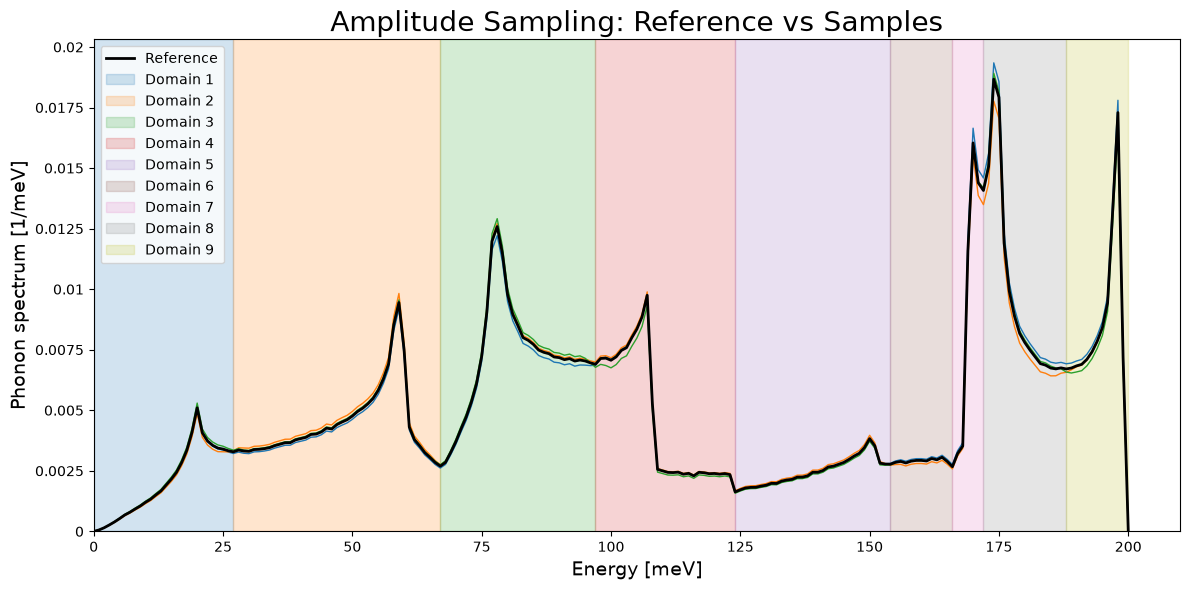

In [11]:
# Plot the reference PDOS and all generated spectra.
fig, ax = plt.subplots(figsize=(12, 6))

plot_PDOS(
    ax,
    list(ensemble),
    ensemble.reference,
    title="Amplitude Sampling: Reference vs Samples",
)

# Highlight the actual perturbation domains recorded by the sampler.
boundaries = ensemble.sampling_blocks[0].boundaries
colors = plt.cm.tab10.colors

for i, (start, end) in enumerate(boundaries):
    ax.axvspan(
        start,
        end,
        color=colors[i % len(colors)],
        alpha=0.20,
        label=f"Domain {i + 1}",
    )

ax.legend(loc="best")
plt.tight_layout()
plt.show()

## 6. Zoom into Two Adjacent Perturbation Domains

A full-spectrum PDOS comparison can hide small changes in neighboring peaks. This final plot zooms into **domains 3 and 4** (zero-based `DOMAIN_INDICES = (2, 3)`) **together on one energy axis**, so their relative peak movements and amplitude changes are directly comparable.

The reference PDOS and all generated spectra remain visible. Each selected perturbation domain is shaded separately, and a small margin shows behavior on either side of the two-domain region. Change the indices to inspect another adjacent pair.

**Optional display settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `DOMAIN_INDICES` | `(2, 3)` | Zero-based indices of the third and fourth domains. |
| `ZOOM_MARGIN` | `0.15` | Fraction of the selected energy span added as padding. |

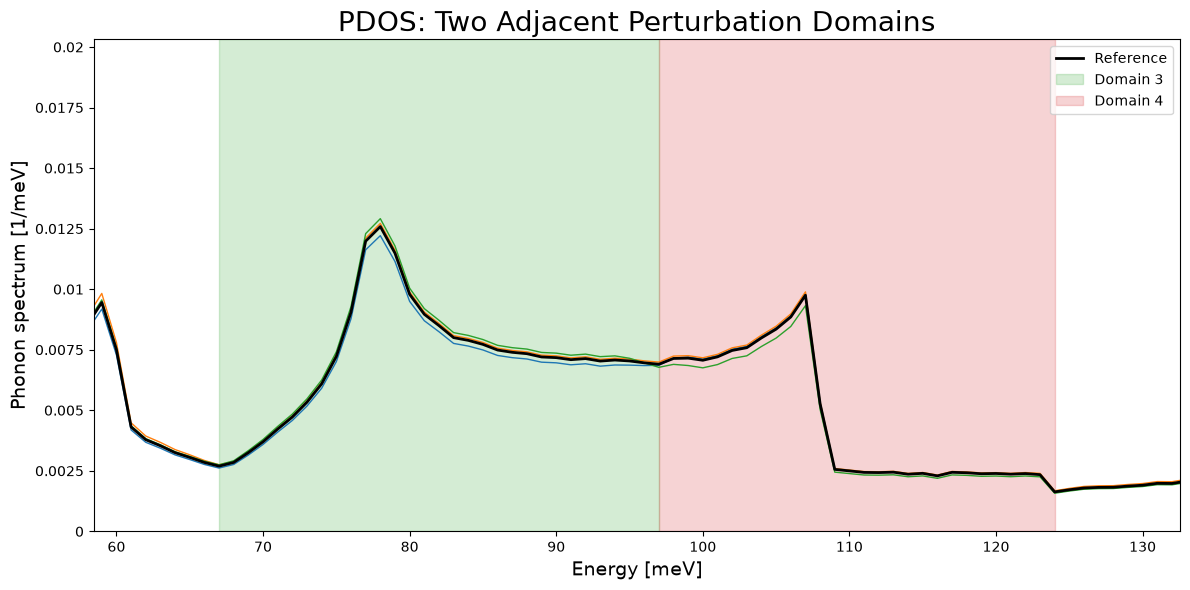

In [12]:
# ---------------------------------------------------------
# Step 6: Zoom into Two Adjacent Perturbation Domains
# ---------------------------------------------------------

DOMAIN_INDICES = (2, 3)  # Zero-based indices: the third and fourth domains.
ZOOM_MARGIN = 0.15

boundaries = ensemble.sampling_blocks[0].boundaries

if len(boundaries) <= max(DOMAIN_INDICES):
    raise ValueError(
        f"At least {max(DOMAIN_INDICES) + 1} domains are required; "
        f"the sampler generated {len(boundaries)}."
    )

# Show both adjacent domains on one axis, preserving their relative positions.
start = min(boundaries[i][0] for i in DOMAIN_INDICES)
end = max(boundaries[i][1] for i in DOMAIN_INDICES)
margin = ZOOM_MARGIN * (end - start)

fig, ax = plt.subplots(figsize=(12, 6))

plot_PDOS(
    ax,
    list(ensemble),
    ensemble.reference,
    title="PDOS: Two Adjacent Perturbation Domains",
)

colors = plt.cm.tab10.colors
for i in DOMAIN_INDICES:
    domain_start, domain_end = boundaries[i]
    ax.axvspan(
        domain_start,
        domain_end,
        color=colors[i % len(colors)],
        alpha=0.20,
        label=f"Domain {i + 1}",
    )

ax.set_xlim(start - margin, end + margin)
ax.legend(loc="best")
plt.tight_layout()
plt.show()